# Lab: Classification with Bank Marketing Data

---

In this lab you will practice building and evaluating **classification models** using a real bank marketing dataset.

The data comes from direct marketing campaigns conducted by a Portuguese banking institution. The campaigns were based on phone calls, and the classification goal is to predict whether a client will subscribe to a term deposit.

We will use the official `bank.csv` sample from the **UCI Bank Marketing dataset**. It is a 10% random sample of the larger dataset and is useful here because we will train several KNN models while choosing a value of `k`.

**Source:** UCI Machine Learning Repository — Bank Marketing  
https://archive.ics.uci.edu/dataset/222/bank+marketing

**Target:** `y`
- `yes` = client subscribed to a term deposit
- `no` = client did not subscribe

### Data Dictionary

| Variable | Description |
|---|---|
| `age` | Client age |
| `job` | Type of job |
| `marital` | Marital status |
| `education` | Education level |
| `default` | Whether the client has credit in default |
| `balance` | Average yearly account balance, in euros |
| `housing` | Whether the client has a housing loan |
| `loan` | Whether the client has a personal loan |
| `contact` | Contact communication type |
| `day` | Day of the month of the last contact |
| `month` | Month of the last contact |
| `duration` | Duration of the last contact, in seconds |
| `campaign` | Number of contacts performed during the current campaign |
| `pdays` | Days since the client was last contacted in a previous campaign (`-1` means not previously contacted) |
| `previous` | Number of contacts performed before the current campaign |
| `poutcome` | Outcome of the previous marketing campaign |
| `y` | Whether the client subscribed to the term deposit (`yes` / `no`) |

#### Understanding the Bank Marketing Features

Think of each row as describing a client at the time of a contact in the **current marketing campaign**.

##### Timeline

```text
CLIENT INFORMATION — already known
│
├── age        → client's age
├── job        → occupation
├── marital    → marital status
├── education  → education level
├── default    → has credit in default?
├── balance    → account balance
├── housing    → has housing loan?
└── loan       → has personal loan?
│
│
▼
PREVIOUS MARKETING CAMPAIGN(S)
│
├── previous   → number of contacts made BEFORE the current campaign
├── poutcome   → outcome of the previous campaign
│
└── Last contact from a previous campaign
        │
        │
        │  pdays
        │  = number of days since this previous contact
        │
        ▼
CURRENT MARKETING CAMPAIGN
│
├── Current contact is about to take place
│
├── month      → month of the current contact
├── day        → day of the current contact
├── contact    → contact method (e.g. cellular / telephone)
├── campaign   → contact number during this campaign (includes the current contact)
│
│                 Example:
│                 Call 1 → Call 2 → Call 3
│                                      ↑
│                                campaign = 3
│
▼
CURRENT PHONE CALL
│
├── duration   → how long this current contact/call lasted
│
▼
CAMPAIGN OUTCOME
│
└── y          → Did the client subscribe to a term deposit?
    
```

### 1. Download and read in the Bank Marketing data.

Download the UCI Bank Marketing archive and extract `bank.csv`.

Then:

1. Read the CSV into a pandas dataframe.
2. Remember that this file uses `;` as the separator.
3. Display the first five rows.

In [3]:
import pandas as pd

df = pd.read_csv("bank.csv", sep=";")
df.head(1000)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,38,blue-collar,married,secondary,no,1370,yes,no,cellular,11,may,472,2,-1,0,unknown,no
996,58,management,married,secondary,no,37,no,no,cellular,18,aug,84,11,-1,0,unknown,no
997,34,management,single,tertiary,no,673,yes,yes,cellular,20,nov,271,1,184,1,failure,no
998,40,services,married,secondary,no,-342,yes,no,unknown,26,may,754,1,-1,0,unknown,no


In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split

from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score

### 2. Conduct an initial exploration of the dataset.

Complete the following:

1. Check the shape of the dataset.
2. Inspect the data types and missing values.
3. Display summary statistics.
4. Check the distribution of the target variable `y`, including percentages.
5. Is this a balanced or imbalanced classification problem? Explain briefly.

In [5]:
df.shape

(4521, 17)

In [6]:
# Check column data types
df.dtypes


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [7]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [8]:
df.describe

<bound method NDFrame.describe of       age            job  marital  education default  balance housing loan  \
0      30     unemployed  married    primary      no     1787      no   no   
1      33       services  married  secondary      no     4789     yes  yes   
2      35     management   single   tertiary      no     1350     yes   no   
3      30     management  married   tertiary      no     1476     yes  yes   
4      59    blue-collar  married  secondary      no        0     yes   no   
...   ...            ...      ...        ...     ...      ...     ...  ...   
4516   33       services  married  secondary      no     -333     yes   no   
4517   57  self-employed  married   tertiary     yes    -3313     yes  yes   
4518   57     technician  married  secondary      no      295      no   no   
4519   28    blue-collar  married  secondary      no     1137      no   no   
4520   44   entrepreneur   single   tertiary      no     1136     yes  yes   

       contact  day month  du

In [9]:
df["y"].value_counts()

y
no     4000
yes     521
Name: count, dtype: int64

In [10]:
# Q5)

#Imbalance in the target variable can lead to biased model performance, where the model may favor the majority class and perform poorly on the minority class. This can result in misleading accuracy metrics and reduced ability to correctly predict the minority class, which is often of greater interest in many applications.

### 3. Define the business problem and choose an evaluation metric.

Assume the bank wants to use the model to decide **which clients should be prioritized for future marketing calls**.

Answer the following:

1. What does a **False Positive** mean in this business problem? What is the cost of this error?
2. What does a **False Negative** mean? What is the cost of this error?
3. Assume the bank considers both errors important, which metric would you choose?
4. Why might **Accuracy** be misleading for this dataset?

#### Answers

1-False Positive (FP): We predict the client will subscribe, but they don't.

2-False Negative (FN): We predict the client will not subscribe, but they do.

3-F1 Score: The harmonic mean of precision and recall.

4-Accuracy can be misleading because the dataset is imbalanced, with more clients who did not subscribe (no) than clients who subscribed (yes). As a result, a model could achieve high accuracy by mostly predicting the majority class (no), while failing to identify actual subscribers, leading to a high number of false negatives.

### 4. Check for information that would lead to data leakage.

The goal is to prioritize clients **before making the marketing call**.

Review the data dictionary and identify any variable that would only become known after the call has already taken place.

1. Which variable should be removed?
2. Why would keeping it create a data leakage / unrealistic prediction problem?
3. Drop the variable from the dataframe.

#### Answers:

duration 
??
drop duration 

In [11]:
# 3. 
#The duration variable.
#The duration variable represents the length of the current call, which is only known after the call has ended. Using it would give the model information that would not be available when predicting whether a client is likely to subscribe before the call. This would make the model unrealistic for the intended use and could inflate its performance.
df = df.drop(columns=['duration'])

### 5. Encode binary categorical variables

Complete the following:

1. Identify the predictor columns containing only `yes` and `no`.
2. Map these columns to `0` and `1`.

> This mapping can be done before the train/test split because it follows a fixed rule and does not learn any information from the dataset.

In [12]:
#identify preictory columns containing only yes and no 
#map these columns as 1 for yes and 0 for no 
binary_columns = ['default', 'housing', 'loan', "y"]
for i in binary_columns:
    df[i] = df[i].map({'yes': 1, 'no': 0})

In [47]:
df['y'].dtype

dtype('int64')

### 6. Prepare the target and split the data.

Complete the following:

1. Create `X` and `y`.
2. Split the data into training and testing sets.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=99,
    stratify=y
)

sc = StandardScaler()
numeric_cols = X.select_dtypes(include=["number"]).columns

X_train_sc = sc.fit_transform(X_train[numeric_cols])
X_test_sc = sc.transform(X_test[numeric_cols])
# Transform only the numeric columns that were used to fit the scaler
X_test_sc = sc.transform(X_test[numeric_cols])

knn = KNeighborsClassifier()
knn.fit(X_train_sc, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [15]:
y_train.value_counts()

y
0    2799
1     365
Name: count, dtype: int64

### 7. Preprocess the training and testing sets

The dataset contains both numerical and categorical variables. Also, there is imbalance in your dataset

#### Part A: Scaling the numerical features

For now, let's transform the numerical ones.

Complete the following:

1. Create a list of numerical columns.
2. Create a `StandardScaler` for the numerical columns.
    - Fit the scaler on the numerical columns of `X_train` only.
    - Use the fitted scaler to transform both `X_train` and `X_test`.
3. Store the scaled numerical values back into their original columns in `X_train` and `X_test`
    - No need to use `.set_output()`
4. Why do we need to scale our data if our model of choice is KNN?


In [16]:
#create a list of numerical columns
numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [17]:
#createq a stanardscaler for numerical columns
#fit the scaler on the numerical columns of X_train only 
#use the fitted scaler to transform both X_train and X_test
scaler = StandardScaler()
scaler.fit(X_train[numerical_columns])
X_train[numerical_columns] = scaler.transform(X_train[numerical_columns])

In [18]:
#store the scaled numerical values back into the original columns of X_train and x-test
X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])

**Q4)**

We scale data when using K-Nearest Neighbors (KNN) because KNN relies on calculating distances between data points. If your features have different scales, the feature with larger numerical values can dominate the distance calculation, causing the model to make poor predictions.

#### Part B: Balancing the training data

Regular `SMOTE` creates synthetic observations by interpolating between neighboring observations. This works well for numerical features, but it is not suitable for categorical features.

Instead, we will use **SMOTENC**, a version of SMOTE designed for datasets containing both numerical and categorical features.

We will apply SMOTENC **before One-Hot Encoding**.

**Why?**

- After One-Hot Encoding, one categorical feature such as `job` becomes several binary columns:

    - `job_admin`, `job_student`, `job_retired`, ...
    
- If we used regular SMOTE after One-Hot Encoding, interpolation could create invalid values such as:

    - `job_admin = 0.4`, `job_student = 0.6`

- which do not represent a real category.

- So applying the resampler at this stage allows us to assign the synthetic sample the most common category among the selected minority-class neighbors.

Complete the following:

1. Identify the categorical columns in the training set.
2. Create a `SMOTENC` resampler:
   - specify which columns are categorical
   - use the default value for `k_neighbors`
   - let the minority class size be **50% of the majority class**
3. Apply the `SMOTENC` **only to the training set**.
4. Compare the training target distribution before and after `SMOTENC`.
5. Why should `SMOTENC` only be applied to the training data?
6. What is the effect of `k_neighbors` when `SMOTENC` creates synthetic observations?

In [19]:
# install if needed
# install if needed
#!pip install -U imbalanced-learn

In [20]:
#from imblearn.datasets import make_imbalance
from imblearn.over_sampling import SMOTENC

In [21]:
cat_col=['job', 'marital', 'education', 'contact', 'month', 'poutcome']

In [22]:
smote_nc = SMOTENC(categorical_features=[X.columns.get_loc(col) for col in cat_col], k_neighbors=5, random_state=42, sampling_strategy=0.5)

In [23]:
x_train_smote, y_train_smote = smote_nc.fit_resample(X_train, y_train)

**Q5)**

SMOTENC should only be applied to training data because the test set must represent the original, unseen data distribution. Resampling the test set could distort the evaluation and make the model's performance metrics unreliable. It could also introduce information from synthetic observations into the evaluation process.

**Q6)**

The k_neighbors parameter determines how many neighboring minority-class observations are considered when generating synthetic observations.
- Smaller k_neighbors: uses fewer neighbors, so synthetic observations are generated from a smaller local neighborhood.
- Larger k_neighbors: uses more neighbors, potentially capturing a broader range of minority-class patterns.

#### Part C: Encoding the categorical features

After resampling our trainig set, we can start encoding.

Complete the following:

1. Create a `OneHotEncoder` for the categorical columns.
    - Use `.set_output()` for this part
    - Fit the encoder on the categorical columns of your **balanced training** set.
    - Use the fitted encoder to transform both the **balanced training** and **unbalanced testing** set.

2. Concatenate the numerical and encoded categorical features to create the final processed training and testing datasets.
    - For the training set, extract the numerical features from the **balanced transformed** training data and combine them with the **encoded categorical** training features.
    - For the test set, extract the numerical features from the **unbalanced transformed** test data and combine them with the **encoded categorical** test features.


In [25]:
# -------------------------
# Encode categorical features
# -------------------------
from sklearn.preprocessing import OneHotEncoder


# Fit on the balanced training categorical features
categorical_cols = cat_col  # ['job', 'marital', 'education', 'contact', 'month', 'poutcome']

encoder = OneHotEncoder(
    drop="first",
    handle_unknown='ignore',
    sparse_output=False
).set_output(transform='pandas')

X_train_cat = encoder.fit_transform(
    x_train_smote[categorical_cols]
)

# Transform the original, unbalanced test categorical features
X_test_cat = encoder.transform(
    X_test[categorical_cols]
)

In [ ]:
# -------------------------
# Combine numerical + encoded categorical features
# -------------------------

# Use the balanced training data produced by SMOTENC
X_train_resampled = x_train_smote.copy()
X_test_resampled = X_test.copy()

numerical_cols = X_train_resampled.columns.difference(c).tolist()

X_train_final = pd.concat(
    [X_train_resampled[numerical_cols].reset_index(drop=True),
     X_train_cat.reset_index(drop=True)],
    axis=1
)

X_test_final = pd.concat(
    [X_test_resampled[numerical_cols].reset_index(drop=True),
     X_test_cat.reset_index(drop=True)],
    axis=1
)

In [27]:
X_train_num = X_train_resampled[numerical_cols]
X_test_num = X_test[numerical_cols]

In [28]:
import pandas as pd

# Final processed training dataset
X_train_final = pd.concat(
    [X_train_num.reset_index(drop=True),
     X_train_cat.reset_index(drop=True)],
    axis=1
)

# Final processed testing dataset
X_test_final = pd.concat(
    [X_test_num.reset_index(drop=True),
     X_test_cat.reset_index(drop=True)],
    axis=1
)
display(X_train_final.head())

,age,balance,campaign,day,default,housing,loan,pdays,previous,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,-0.390432,0.021387,-0.574926,0.115446,-0.137846,0.872750,2.330428,-0.408962,-0.346181,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,-1.545931,-0.488598,-0.574926,-1.465817,-0.137846,-1.145803,2.330428,-0.408962,-0.346181,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.150235,-0.045876,0.064464,-0.127825,-0.137846,0.872750,-0.429106,-0.408962,-0.346181,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.968181,-0.502833,-0.255231,-1.100910,7.254455,-1.145803,2.330428,-0.408962,-0.346181,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.187318,0.755223,-0.255231,-1.344181,-0.137846,-1.145803,-0.429106,-0.408962,-0.346181,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [29]:
print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

print(X_train_final.head())
print(X_test_final.head())

Training shape: (4198, 41)
Testing shape: (1357, 41)
        age   balance  campaign       day   default   housing      loan  \
0 -0.390432  0.021387 -0.574926  0.115446 -0.137846  0.872750  2.330428   
1 -1.545931 -0.488598 -0.574926 -1.465817 -0.137846 -1.145803  2.330428   
2  1.150235 -0.045876  0.064464 -0.127825 -0.137846  0.872750 -0.429106   
3 -0.968181 -0.502833 -0.255231 -1.100910  7.254455 -1.145803  2.330428   
4  0.187318  0.755223 -0.255231 -1.344181 -0.137846 -1.145803 -0.429106   

      pdays  previous  job_blue-collar  ...  month_jul  month_jun  month_mar  \
0 -0.408962 -0.346181              0.0  ...        0.0        0.0        0.0   
1 -0.408962 -0.346181              0.0  ...        1.0        0.0        0.0   
2 -0.408962 -0.346181              0.0  ...        1.0        0.0        0.0   
3 -0.408962 -0.346181              0.0  ...        1.0        0.0        0.0   
4 -0.408962 -0.346181              0.0  ...        0.0        0.0        0.0   

   month_may  m

---

## Logistic Regression

### 8. Train a Logistic Regression classification model.

Now:

1. Create a `LogisticRegression` model.
2. Fit the model 

In [30]:
# Step 2: Instantiate our model
logreg = LogisticRegression()

# Step 3: Fit our model
logreg.fit(X_train_final, y_train_smote)

print(f'Logistic Regression Intercept: {logreg.intercept_}')
print(f'Logistic Regression Coefficient: {logreg.coef_}')

Logistic Regression Intercept: [-2.14171508]
Logistic Regression Coefficient: [[ 0.05118328 -0.07217993 -0.35174361  0.01512602  0.08610229 -0.17434828
  -0.24451816  0.05713502  0.21921406  0.27835248  0.27075302 -0.07849659
   0.9183028   1.2471583   0.02852365 -0.14138843  0.79221678 -0.01992079
  -0.64445071 -0.08569871  0.12280165  0.27183234  0.87723437  0.24980607
  -0.84049278 -0.65812383 -1.7252611   0.08707525  0.82419669 -0.02192177
  -0.74653627 -0.07021249  0.56852142  0.56780364  0.32016763 -0.49299355
   1.42521288  0.28279375 -0.15138558  2.30283935  0.42497701]]


### 9. Evaluate the Logistic Regression model.

Generate predictions and predicted probabilities for the test set.

Calculate:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also:

1. Display the confusion matrix.
2. Plot the ROC curve. 
    - How would you interpret the graph?
3. Based on the business objective from Question 3, which metric should receive the most attention?

Accuracy: 0.8282977155490051
Recall / Sensitivity / True Positive Rate (TPR): 0.3141025641025641
Precision: 0.28
F1 score: 0.29607250755287007


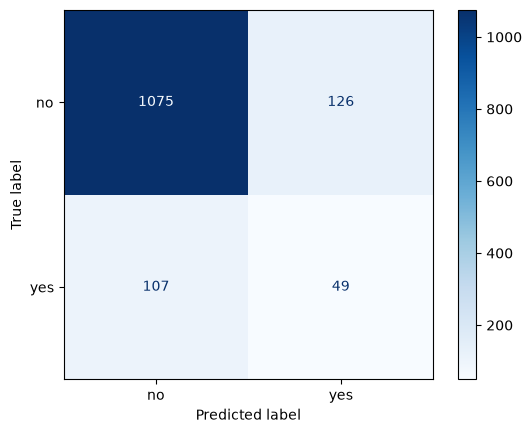

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Using scikit-learn for these metrics...

# Accuracy
# Generate predictions on the test set
y_pred = logreg.predict(X_test_final)

# Accuracy
print(f'Accuracy: {accuracy_score(y_test, y_pred)}')

# Recall / Sensitivity / True Positive Rate (TPR)
print(f'Recall / Sensitivity / True Positive Rate (TPR): {recall_score(y_test, y_pred)}')

# Precision
print(f'Precision: {precision_score(y_test, y_pred)}')

# Specificity / True Negative Rate (TNR) is not defined in scikit-learn

# F1 score
print(f'F1 score: {f1_score(y_test, y_pred)}')

# Look at the confusion matrix before changing the probability threshold...

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
class_names = ["no", "yes"]

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap=plt.cm.Blues)
plt.show();

In [32]:
# probability for the positive class
y_pred_proba = logreg.predict_proba(X_test_final)[:, 1]

# ROC AUC
print(f"ROC AUC: {roc_auc_score(y_test, y_pred_proba)}")

ROC AUC: 0.6912455432438779


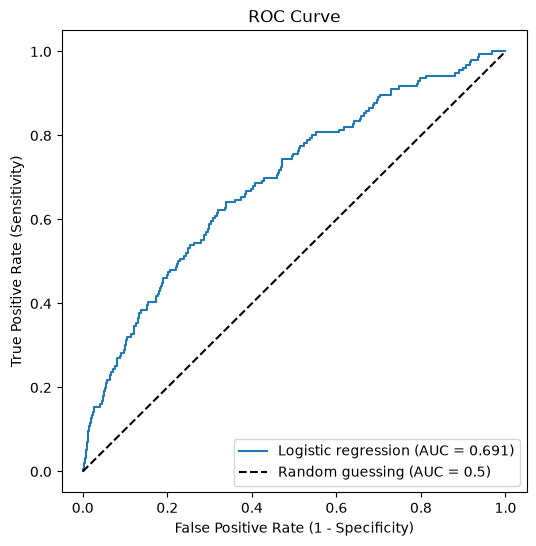

c:\Users\TALAL ALOTHMAN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


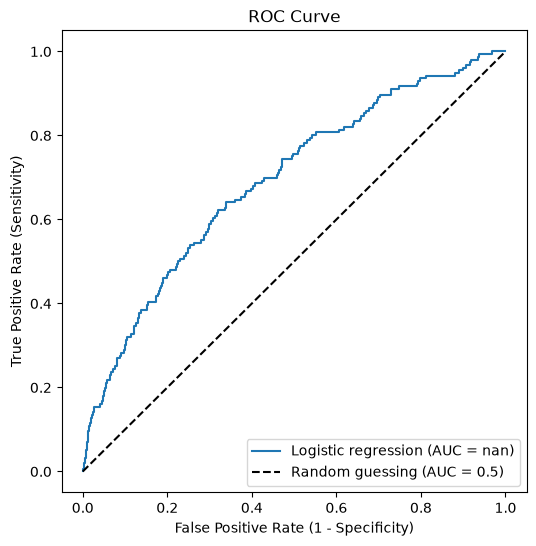

In [33]:
# Calculate ROC curve and ROC AUC score using correct variables and imports
# Calculate ROC curve and ROC AUC score using the correct positive-class probabilities
preds_proba1 = logreg.predict_proba(X_test_final)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, preds_proba1, pos_label=1)
auc_score = roc_auc_score(y_test, preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()
auc_score = roc_auc_score(y_test == 'yes', preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

f1

### 10. Interpret the Logistic Regression coefficients.

1. Extract the fitted Logistic Regression coefficients and convert them into **odds ratios** using:

```python
np.exp(coefficient)
```

2. Create a dataframe containing:

- feature name
- coefficient
- odds ratio

Then:

3. Sort the table by coefficient.
4. Identify features associated with higher odds of subscription.
5. Identify features associated with lower odds of subscription.
6. Interpret at least **two odds ratios** in words.

**Important:**
- Numerical variables were standardized, so a one-unit change for them means approximately a **one standard deviation increase**.
- One-hot encoded categorical variables are interpreted relative to the category that was dropped as the reference group.

In [34]:

# Extract feature names and coefficients
log_reg = logreg  # use the trained LogisticRegression model
feature_names = X_train_final.columns
coefficients = log_reg.coef_[0]
feature_names = X_train_final.columns
coefficients = log_reg.coef_[0]

# Create dataframe
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': np.exp(coefficients)
})

# Sort by coefficient
coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

coef_df

,Feature,Coefficient,Odds Ratio
39,poutcome_success,2.302839,10.002543
36,month_oct,1.425213,4.158743
13,job_retired,1.247158,3.480439
12,job_management,0.918303,2.505035
22,education_secondary,0.877234,2.404241
28,month_dec,0.824197,2.280048
16,job_student,0.792217,2.208286
32,month_jun,0.568521,1.765654
33,month_mar,0.567804,1.764388
40,poutcome_unknown,0.424977,1.529555


In [35]:
# Higher odds of subscription
higher_odds = coef_df[coef_df['Odds Ratio'] > 1]

# Lower odds of subscription
lower_odds = coef_df[coef_df['Odds Ratio'] < 1]

print("Features associated with higher odds:")
print(higher_odds)

print("\nFeatures associated with lower odds:")
print(lower_odds)

Features associated with higher odds:
                Feature  Coefficient  Odds Ratio
39     poutcome_success     2.302839   10.002543
36            month_oct     1.425213    4.158743
13          job_retired     1.247158    3.480439
12       job_management     0.918303    2.505035
22  education_secondary     0.877234    2.404241
28            month_dec     0.824197    2.280048
16          job_student     0.792217    2.208286
32            month_jun     0.568521    1.765654
33            month_mar     0.567804    1.764388
40     poutcome_unknown     0.424977    1.529555
34            month_may     0.320168    1.377359
37            month_sep     0.282794    1.326831
9       job_blue-collar     0.278352    1.320952
21       marital_single     0.271832    1.312367
10     job_entrepreneur     0.270753    1.310951
23   education_tertiary     0.249806    1.283776
8              previous     0.219214    1.245098
20      marital_married     0.122802    1.130660
27            month_aug     0.0

---

## K-Nearest Neighbors

### 11. Train a KNN classification model.

#### Part A: Train KNN models for different values of `k`

Run a KNN model for several odd values of `k` and capture the resulting metric you previously selected in a list.

Every loop iteration should:

1. Train a model with a specific `k` value.
2. Calculate the training score.
3. Calculate the testing score.
4. Create a dictionary storing `k`, the training score and the testing score.
5. Append the dictionary to a `scores` list.

You can test values such as:

```python
range(3, 22, 2)
```

In [36]:
# run a knn for various values of k, and capture the resulting accuracy scores in a list

# Every loop iteration should
# 1. train a model with a specific k value
# 2. calculate the training score
# 3. calculate the testing score
# 4. create a dictionary storing K, train score and  test score
# 5. append the dictionary in the scores list

scores = []

for k in range(3, 22, 2):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_final, y_train_smote)
    train_score = model.score(X_train_final, y_train_smote)
    test_score = model.score(X_test_final, y_test)
    test_score = model.score(X_test_final, y_test)
    score_dict = {'K': k, 'Train Score': train_score, 'Test Score': test_score}
    scores.append(score_dict)
    

#### Part B: Plot the results for the different values of `k`

1. In the same plot, graph the training and testing scores against `k`.
2. Choose a value of `k` that gives strong performance without a large gap between training and test values.

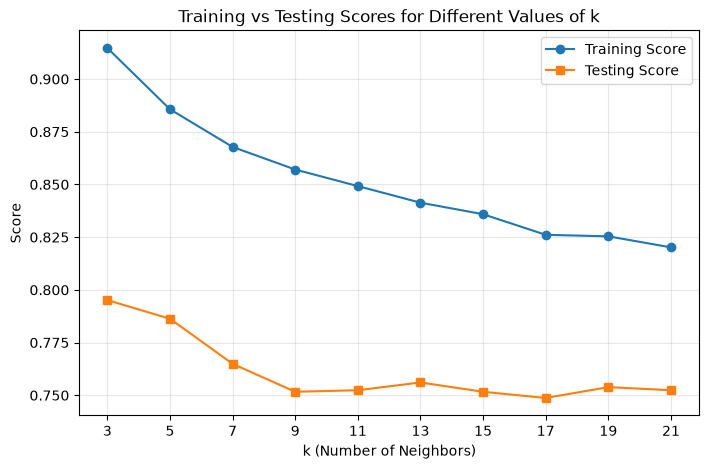

In [37]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
k_values = [score['K'] for score in scores]
train_scores = [score['Train Score'] for score in scores]
test_scores = [score['Test Score'] for score in scores]
plt.plot(k_values, train_scores, marker='o', label='Training Score')
plt.plot(k_values, test_scores, marker='s', label='Testing Score')

plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Score')
plt.title('Training vs Testing Scores for Different Values of k')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()


In [38]:
K=21

<Axes: xlabel='k', ylabel='test_score'>

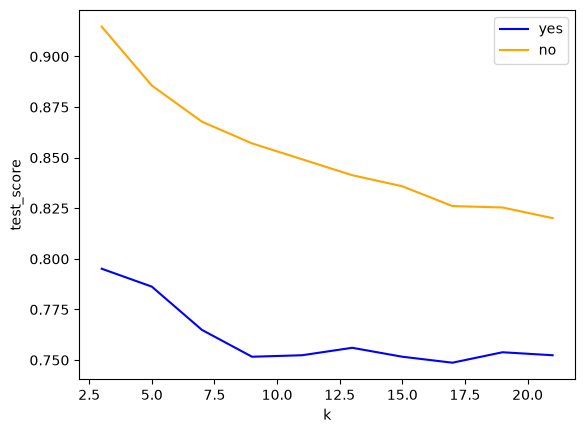

In [39]:
# Create a DataFrame from the existing scores list


# Plot
scores_df = pd.DataFrame(scores)
scores_df = scores_df.rename(columns={'K': 'k', 'Train Score': 'train_score', 'Test Score': 'test_score'})

sns.lineplot(data=scores_df, x='k', y='test_score', color='blue', label='yes')
sns.lineplot(data=scores_df, x='k', y='train_score', color='orange', label='no')

#### Part C:  Build the final KNN model.

Using the `k` value selected in Question 11:

1. Train your final KNN model

In [40]:
#TRAIN WITH K 21
knn = KNeighborsClassifier(n_neighbors=21)
# Train the final KNN model on the same encoded, balanced training set used for selection
knn.fit(X_train_final, y_train_smote)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",21
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### 12. Evaluate the final KNN model.

Using the untouched test set, calculate the same metrics used for Logistic Regression:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also display:

1. The confusion matrix.
2. The ROC curve.

In [41]:
# run a knn for various values of k, and capture the resulting accuracy scores in a list

# Every loop iteration should
# 1. train a model with a specific k value
# 2. calculate the training score
# 3. calculate the testing score
# 4. create a dictionary storing K, train score and  test score
# 5. append the dictionary in the scores list

scores = []

for k in range(21):
    model = KNeighborsClassifier(n_neighbors=k)
    if k == 0:
        continue
    model.fit(X_train_final, y_train_smote)
    train_score = model.score(X_train_final, y_train_smote)
    test_score = model.score(X_test_final, y_test)
    test_score = model.score(X_test_final, y_test)
    score_dict = {'K': k, 'Train Score': train_score, 'Test Score': test_score}
    scores.append(score_dict)
    

Accuracy: 0.8282977155490051
Recall / Sensitivity / True Positive Rate (TPR): 0.3141025641025641
Precision: 0.28
F1 score: 0.29607250755287007


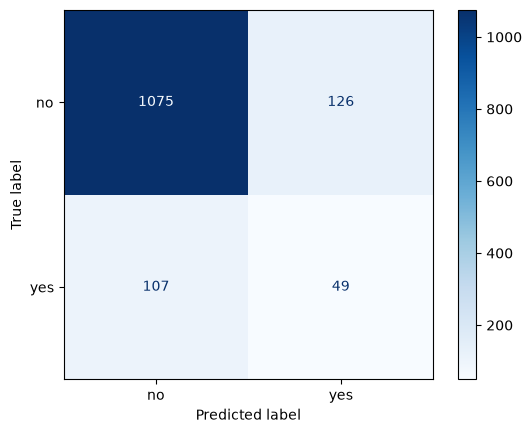

In [42]:


# Using scikit-learn for these metrics...

# Accuracy
# Generate predictions on the test set
y_pred = logreg.predict(X_test_final)

# Accuracy
print(f'Accuracy: {accuracy_score(y_test, y_pred)}')

# Recall / Sensitivity / True Positive Rate (TPR)
print(f'Recall / Sensitivity / True Positive Rate (TPR): {recall_score(y_test, y_pred)}')

# Precision
print(f'Precision: {precision_score(y_test, y_pred)}')

# Specificity / True Negative Rate (TNR) is not defined in scikit-learn

# F1 score
print(f'F1 score: {f1_score(y_test, y_pred)}')

# Look at the confusion matrix before changing the probability threshold...

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
class_names = ["no", "yes"]

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap=plt.cm.Blues)
plt.show();

In [43]:
# probability for the positive class
y_pred_proba = logreg.predict_proba(X_test_final)[:, 1]

# ROC AUC
print(f"ROC AUC: {roc_auc_score(y_test, y_pred_proba)}")

ROC AUC: 0.6912455432438779


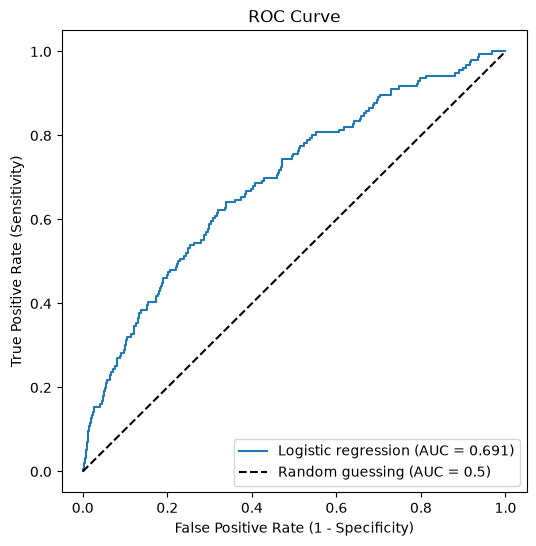

c:\Users\TALAL ALOTHMAN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


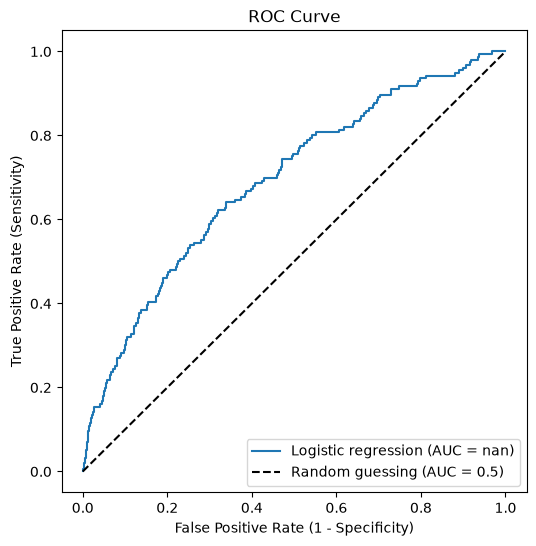

In [44]:
# Calculate ROC curve and ROC AUC score using correct variables and imports
# Calculate ROC curve and ROC AUC score using the correct positive-class probabilities
preds_proba1 = logreg.predict_proba(X_test_final)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, preds_proba1, pos_label=1)
auc_score = roc_auc_score(y_test, preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()
auc_score = roc_auc_score(y_test == 'yes', preds_proba1)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

### 14. Compare the models and make a business recommendation.

Create a table comparing Logistic Regression and KNN using the test-set metrics.

Then answer:

1. Which model performs better for the business objective defined earlier?
2. What trade-off do you see between Precision and Recall?
3. Would you recommend Logistic Regression or KNN to the marketing team? Why?
4. Besides predictive performance, what advantage does Logistic Regression have when the business wants to understand **why** a client is more or less likely to subscribe?

Your recommendation should be based on the business objective — not simply on whichever model has the highest Accuracy.

In [45]:
from sklearn.metrics import balanced_accuracy_score



# Logistic Regression metrics
lr_y_pred = logreg.predict(X_test_final)
lr_y_pred_proba = logreg.predict_proba(X_test_final)[:, 1]

lr_accuracy = accuracy_score(y_test, lr_y_pred)
lr_balanced_accuracy = balanced_accuracy_score(y_test, lr_y_pred)
lr_precision = precision_score(y_test, lr_y_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_y_pred)
lr_f1 = f1_score(y_test, lr_y_pred, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, lr_y_pred_proba)

# KNN metrics
knn_y_pred = knn.predict(X_test_final)
knn_y_pred_proba = knn.predict_proba(X_test_final)[:, 1]

knn_accuracy = accuracy_score(y_test, knn_y_pred)
knn_balanced_accuracy = balanced_accuracy_score(y_test, knn_y_pred)
knn_precision = precision_score(y_test, knn_y_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_y_pred)
knn_f1 = f1_score(y_test, knn_y_pred, zero_division=0)
knn_roc_auc = roc_auc_score(y_test, knn_y_pred_proba)

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN'],
    'Accuracy': [lr_accuracy, knn_accuracy],
    'Balanced Accuracy': [lr_balanced_accuracy, knn_balanced_accuracy],
    'Precision': [lr_precision, knn_precision],
    'Recall': [lr_recall, knn_recall],
    'F1 Score': [lr_f1, knn_f1],
    'ROC AUC': [lr_roc_auc, knn_roc_auc]
})
comparison_df = comparison_df.round(3)
comparison_df

comparison_df = comparison_df.round(3)
comparison_df


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.828,0.605,0.280,0.314,0.296,0.691
1,KNN,0.752,0.584,0.194,0.365,0.253,0.649


1- F1 prioretize both classes 

2-Precision measures the proportion of clients predicted to subscribe who actually subscribe, whereas Recall measures the proportion of actual subscribers correctly identified by the model. Increasing Recall may also increase false positives, meaning the marketing team contacts more clients who ultimately do not subscribe. Higher Precision reduces wasted contacts but may cause the model to miss some potential subscribers. The preferred balance depends on the cost of contacting clients and the value of acquiring new subscribers.

3-I would recommend the model that achieves stronger Recall while maintaining an acceptable Precision and F1 Score on the test set. If both models have comparable predictive performance, Logistic Regression would be a practical choice because it is easier to interpret and explain to the marketing team. However, if KNN demonstrates substantially better performance on the business's priority metric, its predictive advantage should also be considered before making the final decision.

4-Logistic Regression provides interpretable coefficients that can be converted into odds ratios. These indicate how changes in numerical features or differences between categorical groups are associated with the odds of subscribing, while holding other features constant. This helps the marketing team understand which factors are associated with a higher or lower likelihood of subscription and supports more transparent, evidence-based targeting decisions. KNN, in contrast, generally provides less direct insight into how individual features influence predictions.